# CS549 Machine Learning 
# Assignment 3: *K*-means clustering & Simple Neural Network

**Total points: 100**

In this assignment, you will practice (1) implementing K-means clustering, and then apply it on a subset of sign language dataset, and (2) implementing a 2-layer shallow neural network. 

## Section 1: K-means clustering algorithm on image data (50 points)

The `PCA` module provided by `sklearn` package will be used for pre-clustering analysis and post-clustering visualization. You can install `sklearn` by running the following command in terminal:

```
$ pip install sklearn
```

In [40]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

np.random.seed(1)
%matplotlib inline

## Load data

Load data and preprocess.

In [41]:
X_all = np.load(open('X_kmeans.npy', 'rb'))

X1 = X_all[:163, :]
X2 = X_all[163:327, :]
X3 = X_all[327:491, :]

X = np.concatenate((X1, X2, X3), axis=0)
X = np.transpose(X, (1,2,3,0)).reshape(-1, X.shape[0])
print('Shape of X:', X.shape)

Shape of X: (4096, 491)


---
## Analysis

First, we reduce and dimension of the original data to 2, and plot it. The goal of this step is to have some clues of what $k$ values to use, i.e., the number of clusters.

We know that image data of 3 classes are selected, but we use them as if they are unlabelled. Judging from the 2-D plot, there are quite amount of outliers in data, and choosing $k=3$ may well group those outliers into a cluster, instead of grouping into the correct classes. For this we will find out at the last step.

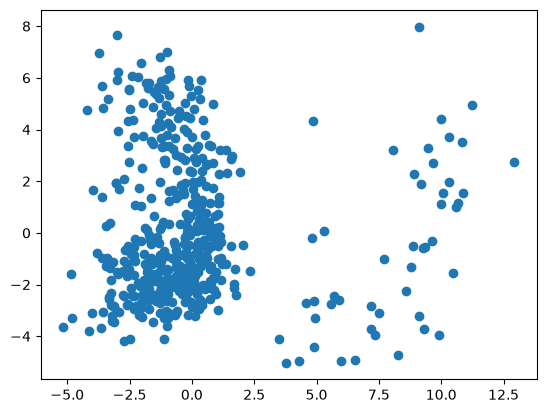

In [42]:
pca = PCA(n_components=2)
pca.fit(X.T)
X_proj = pca.transform(X.T)

# Plot
fig = plt.figure()
plt.scatter(X_proj[:,0], X_proj[:,1])
plt.show()

---
## Task 1. Initialize centroids
**5 point**

The first step of k-means is to randomly initialize a set of centroids. To accomplish this, we simply select $k$ out of the $m$ data points randomly.

**Instructions:**
- Data are stored in columns in `X`. We draw `k` random columns out of it by calling `numpy.random.choice()`. Notice that use the argument `replace=False` is important. Otherwise, it is possible to sample repeated points.
- The returned `centroids` are in shape (n, k).

In [43]:
# Initialize centroids
def init_centroids(X, k):
    """
    Args:
    X -- data, shape (n, m)
    k -- number of clusters
    
    Return:
    centroids -- k randomly picked data points as initial centroids, shape (n, k)
    """
    assert(k > 1)
    np.random.seed(1)
    
    ### START YOUR CODE ### 5 points
    centroids = X[:, np.random.choice(X.shape[1], k, replace=False)]
    ### END YOUR CODE ###
    
    return centroids

In [44]:
# Evaluate Task 1
np.random.seed(1)
X_tmp = np.random.randn(4, 10)
c = init_centroids(X_tmp, k=3)

print('Shape of centroids:', c.shape)
print('centroids:', c)

c_expanded = np.expand_dims(c, axis=1)

Shape of centroids: (4, 3)
centroids: [[-0.52817175 -0.24937038  1.74481176]
 [-0.3224172   0.58281521 -0.17242821]
 [ 0.90159072  0.53035547 -0.12289023]
 [-0.6871727   0.74204416 -1.11731035]]


### Expected output

**Shape of centroids:**(4, 3)
**centroids:**[[-0.52817175 -0.24937038  1.74481176]<br>[-0.3224172   0.58281521 -0.17242821]<br>[ 0.90159072  0.53035547 -0.12289023]]<br>[-0.6871727   0.74204416 -1.11731035]

***

## Task 2. Compute distance between data points and centroids
**15 points**

Next, we need to compute the distances between data points and centroids. More concretely, for each data point `X[:,i]`, we need to compute its distance from the $k$ centroids, i.e., `centroids[:, j]` ($j=1,2,\dots,k$). We will store the computed distances in a $k\times m$ array, in which the element at position $(j, i)$ is the distance between `X[:,i]` and `centroids[:,j]`. The distance we talk about here is Euclidean distance.

There are multiple ways of implementing this computation. The most efficient way is as follows:
- First, expand `centroids` by adding one demension to it, so that its shape changes from (n, k) to (n, 1, k). This can be done by calling `np.expand_dims()`.
- Second, transpose `X` and `centroids_expanded`. The former has shape (m, n) and the latter has shape (k, 1, n). Then the subtraction `S = X.T - centroids_expanded.T` will be in shape (k, m, n). For why it is the case, read the documentation about the broadcasting mechanism of numpy __[here](https://docs.scipy.org/doc/numpy-1.15.1/reference/generated/numpy.broadcast.html)__. 
Next, following the definition of Euclidean distance, we need to:
    - Compute `S**2`, which is in shape (k, m, n).
    - Sum over `S**2` along `axis=2`, which eliminate the last dimension.
    - Apply `numpy.sqrt()` to `S**2`, resulting in an array of shape (k, m), which gives the Euclidean distances.

If you found the above method hard to follow, you can also use an explicit for loop to do the computation.
- You create an empty array `distances` of shape (k, m).
- Then you use a for loop, `for j in range(k):`, and in each step, you compute `S = X - centroids[:,j]` followed by `S**2`, `numpy.sum()`, and `numpy.sqrt()` to get the Euclidean distance, which is stored in a (1,m) array `d`. Then you copy `d` back to the `j`th row of `distances`.

In [45]:
# Compute distances
def compute_distances(X, centroids):
    """
    Args:
    X -- data, shape (n, m)
    centroids -- shape (n, k)
    
    Return:
    distances -- shape (k, m)
    """
    ### START YOUR CODE ###
    centroids_expanded = np.expand_dims(centroids, axis=1)
    distances = np.sqrt(np.sum((X.T - centroids_expanded.T) ** 2, axis=2))
    ### END YOUR CODE ###

    
    return distances

In [46]:
# Evaluate Task 2
np.random.seed(1)
X_tmp = np.random.randn(4, 5)
c = init_centroids(X_tmp, k=2)

dists = compute_distances(X_tmp, c)
print('Distances:', dists)

Distances: [[3.19996571 3.13120276 0.         1.52120576 2.54127667]
 [5.88553536 0.         3.13120276 2.25851302 4.11463616]]


### Expected output

**Distances:**[[3.19996571 3.13120276 0.         1.52120576 2.54127667]<br>[5.88553536 0.         3.13120276 2.25851302 4.11463616]]

***

## Task 3. Find the closest centroid for each data point
**10 point**

Given the distances computed, we can find the closest centroid for each data point. We store this information in a $1\times m$ array, and each element is the index of the closest centroid, i.e., an integer ranging from $0$ to $k-1$.

**Instructions:**
- You can apply `numpy.argmin()` on the `distances` computed in previous step as input, and a proper `axis` argument.

In [47]:
# Find the closest centroid for each data point
def cloeset_centroid(distances):
    """
    Args:
    distances -- numpy array of shape (k, m), output of compute_distances()
    
    Return:
    indices -- numpy array of shape (1, m)
    """
    ### START YOUR CODE ###
    indices = np.argmin(distances, axis=0).reshape(1, -1)
    ### END YOUR CODE ###
    
    return indices

In [48]:
# Evaluate Task 3
np.random.seed(1)
X_tmp = np.random.randn(4, 5)
c = init_centroids(X_tmp, k=2)

dists = compute_distances(X_tmp, c)
closest_indices = cloeset_centroid(dists)

print('Indices of the cloest centroids:', closest_indices)

Indices of the cloest centroids: [[0 1 0 0 0]]


### Expected output

**Indices of the cloest centroids:**[0 1 0 0 0]

***

## Task 4. Update centroids
**10 points**

Given the indices of closest centroid for each data point, you need to update the centroids by computing the average positions of the data points belonging to each cluster ($1,2,\dots,k$).

**Instructions:**
- Because `closest_indices` (output of `closes_centroid()`) is of shape (1, m), you can access the data points whose closest centroid is `j` by using the slice `X[:, closest_indices==j]`.
- Pay attention to the dimension of `new_centroids` computed, and it needs to be the same as `centroids`.

In [49]:
# Update centroids
def update_centroids(X, closest_indices, centroids):
    """
    Args:
    X -- data, shape (n, m)
    cloesest_indices -- output of closest_centroid()
    centroids -- old centroids positions
    
    Return:
    new_centroids -- new centroids positions, shape (n, k)
    """
    ### START YOUR CODE ### 
    new_centroids = np.zeros_like(centroids)
    k = centroids.shape[1]
    for i in range(k):
        points_in_cluster = X[:, closest_indices.flatten() == i]
        if points_in_cluster.shape[1] > 0:
            new_centroids[:, i] = np.mean(points_in_cluster, axis=1)
        else:
            new_centroids[:, i] = centroids[:, i]  # Keep the old centroid if no points are assigned

    ### END YOUR CODE ###
    
    assert(centroids.shape == new_centroids.shape)
    
    return new_centroids

In [50]:
# Evaluate Task 4
np.random.seed(1)
X_tmp = np.random.randn(4, 5)
c = init_centroids(X_tmp, k=2)

dists = compute_distances(X_tmp, c)
closest_indices = cloeset_centroid(dists)
new_c = update_centroids(X_tmp, closest_indices, c)

print('New centroids:', new_c)

New centroids: [[ 0.22215315 -0.61175641]
 [-0.74826922  1.74481176]
 [ 0.47235146 -2.06014071]
 [-0.33818018 -0.17242821]]


### Expected output
**New centroids:**[[ 0.22215315 -0.61175641]<br>[-0.74826922  1.74481176]<br>[ 0.47235146 -2.06014071]<br>[-0.33818018 -0.17242821]]

***

## Task 5. Integrated model
**10 points**

Finally, we combine all the previous steps into one model. We repeatedly find the closest centroid for each data points, and then update the centroids, until the centroids no longer change. The final stable `closest_indices` is then the clustering result.

In [55]:
# K-means
def kmeans(X, k):
    """
    Args:
    X -- data, shape (n, m)
    k -- number of clusters
    
    Return:
    closest_indices -- final assignment of clusters to each data point, shape (1, m)
    centroids -- final positions of centroids
    """
    ### START YOUR CODE ###
    centroids = init_centroids(X, k)
    ### END YOUR CODE ###
    
    old_centroids = None
    while not np.array_equal(old_centroids, centroids):
        # Backup centroids
        old_centroids = np.copy(centroids)
        
        ### START YOUR CODE ###
        # Compute distances
        distances = compute_distances(X, centroids)
        
        # Find cloeset centroid
        
        closest_indices = np.argmin(distances, axis=0)
        
        # Update centroids
        centroids = update_centroids(X, closest_indices, centroids)
        ### END YOUR CODE ###
    
    return closest_indices, centroids


In [56]:
# Evaluate Task 5
closest_indices, centroids = kmeans(X, 3)

print('closest_indices[:10]', closest_indices[:10])
print('closest_indices[70:80]', closest_indices[70:80])
print('closest_indices[140:150]', closest_indices[140:150])
print('closest_indices[210:220]', closest_indices[210:220])

closest_indices[:10] [1 1 0 0 1 1 1 1 1 0]
closest_indices[70:80] [1 1 1 1 1 1 1 1 1 1]
closest_indices[140:150] [1 1 1 1 1 1 1 1 1 0]
closest_indices[210:220] [2 1 1 1 2 2 2 2 2 2]


### Expected output

**closest_indices[:10]**[1 1 0 0 1 1 1 1 1 0]
**closest_indices[70:80]**[1 1 1 1 1 1 1 1 1 1]
**closest_indices[140:150]**[1 1 1 1 1 1 1 1 1 0]
**closest_indices[210:220]**[2 1 1 1 2 2 2 2 2 2]

***

## Visualize clustering result using PCA (ungraded)



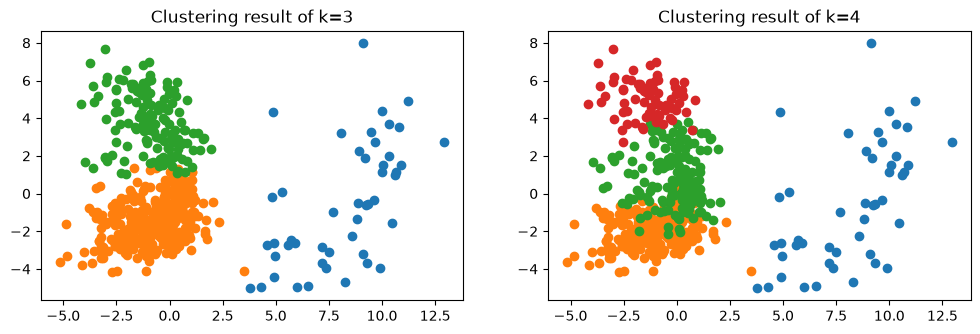

In [57]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca.fit(X.T)
X_proj = pca.transform(X.T)

# Cluster and 
fig = plt.figure(figsize=(12, 3.5))

closest_indices, centroids = kmeans(X, 3)
fig.add_subplot(1, 2, 1)
plt.scatter(X_proj[closest_indices==0, 0], X_proj[closest_indices==0, 1])
plt.scatter(X_proj[closest_indices==1, 0], X_proj[closest_indices==1, 1])
plt.scatter(X_proj[closest_indices==2, 0], X_proj[closest_indices==2, 1])
plt.title('Clustering result of k=3')

closest_indices, centroids = kmeans(X, 4)
fig.add_subplot(1, 2, 2)
plt.scatter(X_proj[closest_indices==0, 0], X_proj[closest_indices==0, 1])
plt.scatter(X_proj[closest_indices==1, 0], X_proj[closest_indices==1, 1])
plt.scatter(X_proj[closest_indices==2, 0], X_proj[closest_indices==2, 1])
plt.scatter(X_proj[closest_indices==3, 0], X_proj[closest_indices==3, 1])
plt.title('Clustering result of k=4')

plt.show()

***
 Let's compare with the ground truth, i.e., labeled data.

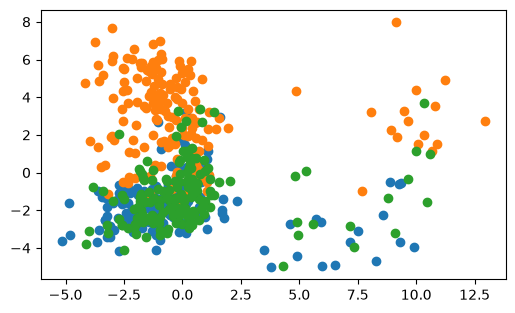

In [58]:
fig = plt.figure(figsize=(6, 3.5))

plt.scatter(X_proj[:163, 0], X_proj[:163, 1])
plt.scatter(X_proj[163:327, 0], X_proj[163:327, 1])
plt.scatter(X_proj[327:491, 0], X_proj[327:491, 1])

plt.show()

Looks like k-means cannot distinguish the 2nd and 3rd classes, and it is also sensitive to outliers.

## Section 2: Simple Neural Network


**Total points: 50**

In this section, you will implement a 2-layer shallow neural network model. 

We will use the model to conduct the same binary classification task, i.e., classify two categories of the sign language dataset. 

The input size is the number of pixels in a image ($64\times 64$). The size of hidden layer is determined by a hyperparameter `n_h`, and the size of output layer is 1.

In [59]:
import numpy as np
import matplotlib.pyplot as plt
from utils import *
# import importlib
# importlib.reload(utils)

%matplotlib inline
np.random.seed(1)

In [60]:
# Load data
### DO NOT CHANGE THE CODE BELOW ###
X_train, Y_train, X_test, Y_test = load_data()

print(X_train.shape)
print(Y_train.shape)
print(X_test.shape)
print(Y_test.shape)

(4096, 286)
(1, 286)
(4096, 125)
(1, 125)


### Step 1. Intialize parameters
**5 point**

The parameters associated with the hidden layer are $W^{[1]}$ and $b^{[1]}$, and the parameters associated with the output layer are $W^{[2]}$ and $b^{[2]}$.

We use **tanh** as acitivation function for hidden layer, and **sigmoid** for output layer.

**Instructions:**
- Initialize parameters randomly
- Use `np.random.randn((size_out, size_in))*0.01` to initialize $W^{[l]}$, in which `size_out` is the output size of current layer, and `size_in` is the input size from previous layer. 
- Use `np.zeros()` to initialize $b^{[l]}$

In [61]:
def init_params(n_i, n_h, n_o):
    """
    Args:
    n_i -- size of input layer
    n_h -- size of hidden layer
    n_o -- size of output layer
    
    Return:
    params -- a dict object containing all parameters:
        W1 -- weight matrix of layer 1
        b1 -- bias vector of layer 1
        W2 -- weight matrix of layer 2
        b2 -- bias vector of layer 2
    """
    np.random.seed(2) # DO NOT change this line! 
    
    ### START YOUR CODE ###
    W1 = np.random.randn(n_h, n_i) * 0.01
    b1 = np.zeros((n_h, 1))
    W2 = np.random.randn(n_o, n_h) * 0.01
    b2 = np.zeros((n_o, 1))
    ### END YOUR CODE ###
    
    params = {'W1': W1, 'b1': b1, 'W2': W2, 'b2': b2}
    
    return params

In [62]:
# Evaluate Step 1
### DO NOT CHANGE THE CODE BELOW ###
ps = init_params(3, 4, 1)
print('W1 =', ps['W1'])
print('b1 =' ,ps['b1'])
print('W2 =', ps['W2'])
print('b2 =', ps['b2'])

W1 = [[-0.00416758 -0.00056267 -0.02136196]
 [ 0.01640271 -0.01793436 -0.00841747]
 [ 0.00502881 -0.01245288 -0.01057952]
 [-0.00909008  0.00551454  0.02292208]]
b1 = [[0.]
 [0.]
 [0.]
 [0.]]
W2 = [[ 0.00041539 -0.01117925  0.00539058 -0.0059616 ]]
b2 = [[0.]]


**Expected output**

**W1 =**|[[-0.00416758 -0.00056267 -0.02136196] <br>[ 0.01640271 -0.01793436 -0.00841747] <br> [ 0.00502881 -0.01245288 -0.01057952]<br>[-0.00909008  0.00551454  0.02292208]]|
**b1 =**|[[0.]<br>[0.]<br>[0.]<br>[0.]]|
**W2 =**|[[ 0.00041539 -0.01117925  0.00539058 -0.0059616 ]]|
**b2 =**|[[0.]]|

***

### Step 2. Forward propagation

**10 points**

Use the following fomulas to implement forward propagation:
- $Z^{[1]} = W^{[1]}X + b^{[1]}$
- $A^{[1]} = tanh(Z^{[1]})$ --> use `np.tanh` function
- $Z^{[2]} = W^{[2]}A^{[1]} + b^{[2]}$
- $A^{[2]} = \sigma(Z^{[2]})$ --> directly use the `sigmoid` function provided in `utils` package

In [63]:
def forward_prop(X, params):
    """
    Args:
    X -- input data of shape (n_in, m)
    params -- a python dict object containing all parameters (output of init_params)
    
    Return:
    A2 -- the activation of the output layer
    cache -- a python dict containing all intermediate values for later use in backprop
             i.e., 'Z1', 'A1', 'Z2', 'A2'
    """
    m = X.shape[1]
    
    # Retrieve parameters
    ### START YOUR CODE ###
    W1 = params['W1']
    b1 = params['b1']
    W2 = params['W2']
    b2 = params['b2']
    ### END YOUR CODE ###
    
    # Implement forward propagation
    ### START YOUR CODE ###
    Z1 = np.dot(W1, X) + b1
    A1 = np.tanh(Z1)
    Z2 = np.dot(W2, A1) + b2
    A2 = sigmoid(Z2)
    ### END YOUR CODE ###
    
    assert A1.shape[1] == m
    assert A2.shape[1] == m
    
    cache = {'Z1': Z1, 'A1': A1, 'Z2': Z2, 'A2': A2}
    
    return A2, cache


In [64]:
# Evaluate Step 2
### DO NOT CHANGE THE CODE BELOW ###
X_tmp, params_tmp = forwardprop_testcase()

A2, cache = forward_prop(X_tmp, params_tmp)
print('mean(Z1) =', np.mean(cache['Z1']))
print('mean(A1) =', np.mean(cache['A1']))
print('mean(Z2) =', np.mean(cache['Z2']))
print('mean(A2) =', np.mean(cache['A2']))

mean(Z1) = 0.13208981347443063
mean(A1) = -0.012947502242342993
mean(Z2) = -0.028697749001905425
mean(A2) = 0.5329353691451202


**Expected output**

|**mean(Z1) =**|0.13208981347443063|
|**mean(A1) =**|-0.01294750224234301|
|**mean(Z2) =**|-0.028697749001905536|
|**mean(A2) =**|0.5329353691451202|

***

### Step 3. Backward propagation
**15 points**

Use the following formulas to implement backward propagation:
- $dZ^{[2]} = A^{[2]} - Y$
- $dW^{[2]} = \frac{1}{m}dZ^{[2]}A^{[1]T}$ --> $m$ is the number of examples
- $db^{[2]} = \frac{1}{m}$ np.sum( $dZ^{[2]}$, axis=1, keepdims=True)
- $dA^{[1]} = W^{[2]T}dZ^{[2]}$
- $dZ^{[1]} = dA^{[1]}*g'(Z^{[1]})$
    - Here $*$ denotes element-wise multiply
    - $g(z)$ is the tanh function, therefore its derivative $g'(Z^{[1]}) = 1 - (g(Z^{[1]}))^2 = 1 - (A^{[1]})^2$
- $dW^{[1]} = \frac{1}{m} dZ^{[1]}X^T$
- $db^{[1]} = \frac{1}{m}$ np.sum( $dZ^{[1]}$, axis=1, keepdims=True)

In [65]:
def backward_prop(X, Y, params, cache):
    """
    Args:
    X -- input data of shape (n_in, m)
    Y -- input label of shape (1, m)
    params -- a python dict containing all parameters
    cache -- a python dict containing 'Z1', 'A1', 'Z2' and 'A2' (output of forward_prop)
    
    Return:
    grads -- a python dict containing the gradients w.r.t. all parameters,
             i.e., dW1, db1, dW2, db2
    """
    m = X.shape[1]
    
    # Retrieve parameters
    ### START YOUR CODE ###
    W1 = params['W1']
    W2 = params['W2']
    ### END YOUR CODE ###
    
    # Retrive intermediate values stored in cache
    ### START YOUR CODE ###
    A1 = cache['A1']
    A2 = cache['A2']
    ### END YOUR CODE ###
    
    # Implement backprop
    ### START YOUR CODE ###
    dZ2 = A2 - Y
    dW2 = (1 / m) * np.dot(dZ2, A1.T)
    db2 = (1 / m) * np.sum(dZ2, axis=1, keepdims=True)
    dA1 = np.dot(W2.T, dZ2)
    dZ1 = dA1 * (1 - A1 ** 2)
    dW1 = (1 / m) * np.dot(dZ1, X.T)
    db1 = (1 / m) * np.sum(dZ1, axis=1, keepdims=True)
    ### END YOUR CODE ###
    
    grads = {'dW1': dW1, 'db1': db1, 'dW2': dW2, 'db2': db2}
    
    return grads


In [66]:
# Evaluate Step 3
### DO NOT CHANGE THE CODE BELOW ###
X_tmp, Y_tmp, params_tmp, cache_tmp = backprop_testcase()

grads = backward_prop(X_tmp, Y_tmp, params_tmp, cache_tmp)
print('mean(dW1)', np.mean(grads['dW1']))
print('mean(db1)', np.mean(grads['db1']))
print('mean(dW2)', np.mean(grads['dW2']))
print('mean(db2)', np.mean(grads['db2']))

mean(dW1) -0.039558211695590706
mean(db1) 0.001467912358907287
mean(dW2) 0.1250823230639841
mean(db2) 0.13293536800000003


**Expected output**

|**mean(dW1) =**|-0.039558211695590706|
|**mean(db1) =**|0.001467912358907287|
|**mean(dW2) =**|0.1250823230639841|
|**mean(db2) =**|0.13293536800000003|

***

### Step 4. Update parameters
**5 point**

Update $W^{[1]}, b^{[1]}, W^{[2]}, b^{[2]}$ accordingly:
- $W^{[1]} = W^{[1]} - \alpha\ dW^{[1]}$
- $b^{[1]} = b^{[1]} - \alpha\ db^{[1]}$
- $W^{[2]} = W^{[2]} - \alpha\ dW^{[2]}$
- $b^{[2]} = b^{[2]} - \alpha\ db^{[2]}$

In [67]:
def update_params(params, grads, alpha):
    """
    Args:
    params -- a python dict containing all parameters
    grads -- a python dict containing the gradients w.r.t. all parameters (output of backward_prop)
    alpha -- learning rate
    
    Return:
    params -- a python dict containing all updated parameters
    """
    # Retrieve parameters
    ### START YOUR CODE ###
    W1 = params['W1']
    b1 = params['b1']
    W2 = params['W2']
    b2 = params['b2']
    ### END YOUR CODE ###
    
    # Retrieve gradients
    ### START YOUR CODE ###
    dW1 = grads['dW1']
    db1 = grads['db1']
    dW2 = grads['dW2']
    db2 = grads['db2']
    ### END YOUR CODE ###
    
    # Update each parameter
    ### START YOUR CODE ###
    W1 = W1 - alpha * dW1
    b1 = b1 - alpha * db1
    W2 = W2 - alpha * dW2
    b2 = b2 - alpha * db2
    ### END YOUR CODE ###
    
    params = {'W1': W1, 'b1': b1, 'W2': W2, 'b2': b2}
    
    return params


In [68]:
# Evaluate Step 4
### DO NOT CHANGE THE CODE BELOW ###
params_tmp, grads_tmp = update_params_testcase()

params = update_params(params_tmp, grads_tmp, 0.01)
print('W1 =', params['W1'])
print('b1 =', params['b1'])
print('W2 =', params['W2'])
print('b2 =', params['b2'])

W1 = [[-1.9959083  -1.06667372 -0.75475925]
 [ 0.29418098 -0.98950432 -1.22186039]
 [-0.27355221 -1.6082775   0.11104952]
 [-0.14229044  1.07321512  0.4208789 ]
 [ 0.59648267  0.86048013 -1.60750032]]
b1 = [[-0.00062513]
 [ 0.00046574]
 [ 0.00069734]
 [-0.0002741 ]
 [-0.00033725]]
W2 = [[ 1.08049444 -0.25269532  1.0989616   0.20063139  1.45914531]]
b2 = [[-0.00132935]]


**Expected output**

|**W1 =**|[[-1.9959083  -1.06667372 -0.75475925]<br>[ 0.29418098 -0.98950432 -1.22186039]<br>[-0.27355221 -1.6082775   0.11104952]<br>[-0.14229044  1.07321512  0.4208789 ]<br>[ 0.59648267  0.86048013 -1.60750032]]|
|**b1 =**|[[-0.00062513]<br>[ 0.00046574]<br>[ 0.00069734]<br>[-0.0002741 ]<br>[-0.00033725]]|
|**W2 =**|[[ 1.08049444 -0.25269532  1.0989616   0.20063139  1.45914531]]|
|**b2 =**|[[-0.00132935]]|

***

### Step 5. Integrated model
**8 points**

Integrate `init_params`, `forward_prop`, `backward_prop` and `update_params` into one model.

In [69]:
def nn_model(X, Y, n_h, num_iters=10000, alpha=0.01, verbose=False):
    """
    Args:
    X -- training data of shape (n_in, m)
    Y -- training label of shape (1, m)
    n_h -- size of hidden layer
    num_iters -- number of iterations for gradient descent
    verbose -- print cost every 1000 steps
    
    Return:
    params -- parameters learned by the model. Use these to make predictions on new data
    """
    np.random.seed(3)
    m = X.shape[1]
    n_in = X.shape[0]
    n_out = 1
    
    # Initialize parameters and retrieve them
    params = init_params(n_in, n_h, n_out)
    W1 = params['W1']
    b1 = params['b1']
    W2 = params['W2']
    b2 = params['b2']
    
    # Gradient descent loop
    for i in range(num_iters):
        ### START YOUR CODE ###
        # Forward propagation
        A2, cache = forward_prop(X, params)
        
        # Backward propagation
        grads = backward_prop(X, Y, params, cache)
        
        # Update parameters
        params = update_params(params, grads, alpha)
        ### END YOUR CODE ###
        
        # Compute cost
        cost = -(1/m) * np.sum(np.log(A2) * Y + np.log(1 - A2) * (1 - Y))
        
        # Print cost
        if i % 1000 == 0 and verbose:
            print('Cost after iter {}: {}'.format(i, cost))
    
    return params


In [70]:
# Evaluate Step 5
### DO NOT CHANGE THE CODE BELOW ###
X_tmp, Y_tmp = nn_model_testcase()

params_tmp = nn_model(X_tmp, Y_tmp, n_h=5, num_iters=5000, alpha=0.01)
print('W1 =', params_tmp['W1'])
print('b1 =', params_tmp['b1'])
print('W2 =', params_tmp['W2'])
print('b2 =', params_tmp['b2'])

W1 = [[ 0.728558   -0.60417473 -0.24274211]
 [ 0.88560809 -0.67439594 -0.3043778 ]
 [-0.20781606 -0.59195986 -0.27344463]
 [-0.51914662  0.61152697  0.17713134]
 [ 0.00864946 -0.25198231 -0.1411225 ]]
b1 = [[ 0.29073376]
 [ 0.29189656]
 [ 0.28876041]
 [-0.32656432]
 [ 0.09711243]]
W2 = [[-1.25312586 -1.40689892 -0.69967068  1.13815825 -0.31472553]]
b2 = [[-0.80345148]]


**Expected output**

|**W1 =**|[[ 0.728558   -0.60417473 -0.24274211]<br>[ 0.88560809 -0.67439594 -0.3043778 ]<br>[-0.20781606 -0.59195986 -0.27344463]<br>[-0.51914662  0.61152697  0.17713134]<br>[ 0.00864946 -0.25198231 -0.1411225 ]]|
|**b1 =**|[[ 0.29073376]<br>[ 0.29189656]<br>[ 0.28876041]<br>[-0.32656432]<br>[ 0.09711243]]|
|**W2 =**|[[-1.25312586 -1.40689892 -0.69967068  1.13815825 -0.31472553]]|
|**b2 =**|[[-0.80345148]]|

***

### Step 6. Predict
**5 point**

Use the learned parameters to make predictions on new data. 
- Compute $A^{[2]}$ by calling `forward_prop`. Note that the `cache` returned will not be used in making predictions.
- Convert $A^{[2]}$ into a vector of 0 and 1.

In [71]:
def predict(X, params):
    """
    Args:
    X -- input data of shape (n_in, m)
    params -- a python dict containing the learned parameters
    
    Return:
    pred -- predictions of model on X, a vector of 0s and 1s
    """
    ### START YOUR CODE ###
    A2, _ = forward_prop(X, params)
    pred = (A2 > 0.5).astype(float) # Convert to a vector of 0 and 1.
    ### END YOUR CODE ###
    
    return pred


In [72]:
# Evaluate Task 1.6
# NOTE: the X_tmp and params_tmp are the ones generated in evaluating Task 1.5 (two cells above)
### DO NOT CHANGE THE CODE BELOW ###

pred = predict(X_tmp, params_tmp)
print('predictions = ', pred)

predictions =  [[0. 1. 0. 0. 1.]]


**Expected output**

|**predictions =**|[[0. 1. 0. 0. 1.]]|

***

### Step 7. Train and evaluate

**2 point**

Train the neural network model on X_train and Y_train, and evaluate it on X_test and Y_test.

You can use the code from the previous assignment for Logistic Regression and Evaluation Metrics to compute the accuracy of your predictions.

In [73]:
# Train the model on X_train and Y_train, and print cost
# DO NOT change the hyperparameters, so that your output matches the expected one.
params = nn_model(X_train, Y_train, n_h = 10, num_iters=10000, verbose=True)

# Make predictions on X_test
predictions = predict(X_test, params)

# Compute accuracy by comparing predictions and Y_test
### START YOUR CODE ###
acc = np.mean(predictions == Y_test)
### END YOUR CODE ###
print('Accuracy = {0:.2f}%'.format(acc * 100))


Cost after iter 0: 0.6931077265775999
Cost after iter 1000: 0.27207961454946855
Cost after iter 2000: 0.05465336307540399
Cost after iter 3000: 0.024301511012142268
Cost after iter 4000: 0.014582035344859117
Cost after iter 5000: 0.010122447576927747
Cost after iter 6000: 0.007637962766021932
Cost after iter 7000: 0.006078964716600651
Cost after iter 8000: 0.005019538027066649
Cost after iter 9000: 0.004257448979301009
Accuracy = 95.20%


**Expected output**

|**Cost after iter 0:**|0.6931077265775999|
|**Cost after iter 1000:**|0.2482306581297105|
|**Cost after iter 2000:**|0.05471507033938196|
|**Cost after iter 3000:**|0.024326463013581715|
|**Cost after iter 4000:**|0.014595754197204438|
|**Cost after iter 5000:**|0.010131520880123288|
|**Cost after iter 6000:**|0.00764463387660483|
|**Cost after iter 7000:**|0.0060842030981856435|
|**Cost after iter 8000:**|0.005023835721723831|
|**Cost after iter 9000:**|0.0042610856757679645|
|**Accuracy =** |95.20%|

***